### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/09/02

Project description
- Large-scale scientific experiments and simulations generate substantial volumes of data that must be transferred to and accessed from distributed computing facilities. These workflows involve thousands of concurrent data-access and data-movement operations. Because the same datasets are often accessed repeatedly by users at the same institution or within the same geographic region, regional caching can reduce redundant transfers by storing and sharing frequently requested data closer to users.

- By reducing repeated wide-area network transfers, regional caching can lower network traffic, decrease data-access latency, and improve overall application performance. However, effective caching and resource planning require a better understanding of how network utilization changes over time.

- This project investigates network utilization data as a time-series forecasting problem. We will examine usage patterns and dataset characteristics, develop multivariate and multi-step forecasting models, and evaluate machine-learning approaches such as Temporal Convolutional Networks (TCNs). The goal is to produce accurate longer-term forecasts that can support cache management, resource allocation across compute, storage, and network systems, and future traffic-engineering decisions.

### Explore dataset

In [2]:
from pathlib import Path
import pandas as pd

# After unzipping the archives, use the data-only folder (or the same folder inside xcache-ts).
data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df')]
data_dir = next((path for path in data_dirs if path.exists()), None)
if data_dir is None:
    raise FileNotFoundError('Please unzip xcache-ts-2024-data_only (1).tar.gz first.')

files = sorted(path for path in data_dir.iterdir() if path.is_file())
print(f'Data folder: {data_dir.resolve()}')
print(f'Number of data files: {len(files)}')
[path.name for path in files]

Data folder: /Users/dengyingxin/Desktop/xcache/xcache-ts-df
Number of data files: 42


['bost-2308-2403-daily-ml',
 'bost-2308-2403-daily-ts-access_count',
 'bost-2308-2403-daily-ts-access_size',
 'bost-2308-2403-daily-ts-hit_count',
 'bost-2308-2403-daily-ts-hit_size',
 'bost-2308-2403-daily-ts-miss_count',
 'bost-2308-2403-daily-ts-miss_size',
 'bost-2308-2403-hourly-ml',
 'bost-2308-2403-hourly-ts-access_count',
 'bost-2308-2403-hourly-ts-access_size',
 'bost-2308-2403-hourly-ts-hit_count',
 'bost-2308-2403-hourly-ts-hit_size',
 'bost-2308-2403-hourly-ts-miss_count',
 'bost-2308-2403-hourly-ts-miss_size',
 'chic-2210-2403-daily-ml',
 'chic-2210-2403-daily-ts-access_count',
 'chic-2210-2403-daily-ts-access_size',
 'chic-2210-2403-daily-ts-hit_count',
 'chic-2210-2403-daily-ts-hit_size',
 'chic-2210-2403-daily-ts-miss_count',
 'chic-2210-2403-daily-ts-miss_size',
 'chic-2210-2403-hourly-ml',
 'chic-2210-2403-hourly-ts-access_count',
 'chic-2210-2403-hourly-ts-access_size',
 'chic-2210-2403-hourly-ts-hit_count',
 'chic-2210-2403-hourly-ts-hit_size',
 'chic-2210-2403-hour

In [3]:
# Inspect one multivariate daily dataset: six network-utilization variables.
sample_path = data_dir / 'socal-2006-2403-daily-ml'
df = pd.read_pickle(sample_path)

# Convert data-volume columns from bytes to terabytes (TB).
size_columns = ['access_size', 'hit_size', 'miss_size']
BYTES_PER_TB = 1000 ** 4
df[size_columns] = df[size_columns] / BYTES_PER_TB
print(f'Shape: {df.shape}')
print(f'Time range: {df.index.min()} to {df.index.max()}')
display(df.head())
df.info()

# A compact numerical overview for preliminary analysis.
display(df.describe().T)

# Verify the two deterministic cache-data relationships for every day.
count_difference = df['access_count'] - (df['hit_count'] + df['miss_count'])
size_difference = df['access_size'] - (df['hit_size'] + df['miss_size'])
validation_summary = pd.DataFrame({
    'relationship': ['access_count = hit_count + miss_count',
                     'access_size = hit_size + miss_size'],
    'days_valid': [(count_difference == 0).sum(),
                   (size_difference.abs() < 1e-10).sum()],
    'days_invalid': [(count_difference != 0).sum(),
                     (size_difference.abs() >= 1e-10).sum()],
    'maximum_absolute_difference': [count_difference.abs().max(),
                                    size_difference.abs().max()]
})
display(validation_summary)

Shape: (1401, 6)
Time range: 2020-05-31 00:00:00 to 2024-03-31 00:00:00


,access_count,access_size,hit_count,hit_size,miss_count,miss_size
data_start_time_datetime,,,,,,
2020-05-31,9615,7.247672,5648,4.306678,3967,2.940994
2020-06-01,37391,23.700100,22909,14.073827,14482,9.626272
2020-06-02,61088,34.787786,25539,11.936270,35549,22.851516
2020-06-03,35953,26.438742,23689,18.058082,12264,8.380659
2020-06-04,44218,40.089986,31600,26.688669,12618,13.401317


<class 'pandas.DataFrame'>
DatetimeIndex: 1401 entries, 2020-05-31 to 2024-03-31
Freq: D
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   access_count  1401 non-null   int64  
 1   access_size   1401 non-null   float64
 2   hit_count     1401 non-null   int64  
 3   hit_size      1401 non-null   float64
 4   miss_count    1401 non-null   int64  
 5   miss_size     1401 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 76.6 KB


,count,mean,std,min,25%,50%,75%,max
access_count,1401.0,22083.172020,18451.414204,0.0,8969.000000,17070.000000,29805.000000,105999.000000
access_size,1401.0,27.497580,31.341529,0.0,7.281416,18.710906,36.659928,247.289341
hit_count,1401.0,15777.190578,12827.658704,0.0,6491.000000,13099.000000,22454.000000,92717.000000
hit_size,1401.0,19.048345,26.299824,0.0,3.209862,10.630505,24.811248,246.300854
miss_count,1401.0,6305.981442,8811.320129,0.0,652.000000,2682.000000,8285.000000,64209.000000
miss_size,1401.0,8.449234,17.790091,0.0,0.237548,2.233509,8.355927,199.277821


,relationship,days_valid,days_invalid,maximum_absolute_difference
0,access_count = hit_count + miss_count,1401,0,0.000000e+00
1,access_size = hit_size + miss_size,1401,0,2.842171e-14


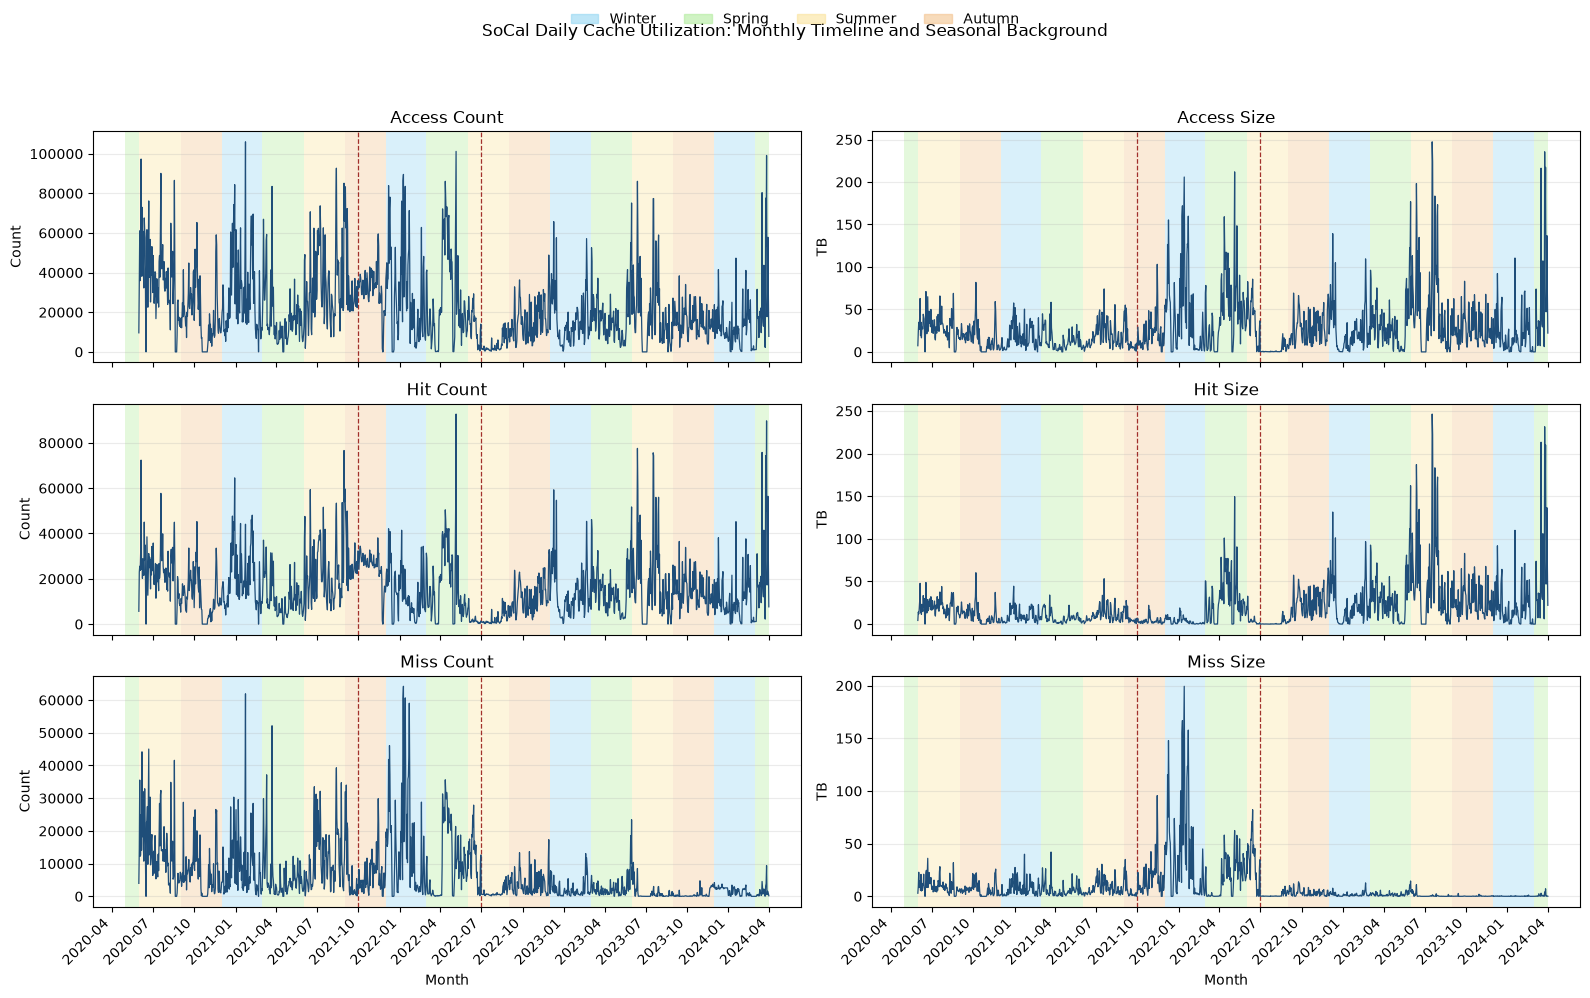

In [4]:
# Visualize daily trends. Background colors identify meteorological seasons; ticks mark months.
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

season_colors = {
    'Winter': "#94D6F2",  # Dec-Feb
    'Spring': "#B2EB9D",  # Mar-May
    'Summer': "#FBE39C",  # Jun-Aug
    'Autumn': "#F3C38F"   # Sep-Nov
}

def add_season_background(ax, start_date, end_date):
    boundaries = pd.date_range(start_date.normalize().replace(day=1),
                               end_date + pd.offsets.MonthBegin(1), freq='MS')
    for start in boundaries:
        end = min(start + pd.offsets.MonthBegin(1), end_date)
        if end <= start:
            continue
        season = {12: 'Winter', 1: 'Winter', 2: 'Winter',
                  3: 'Spring', 4: 'Spring', 5: 'Spring',
                  6: 'Summer', 7: 'Summer', 8: 'Summer',
                  9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}[start.month]
        ax.axvspan(start, end, color=season_colors[season], alpha=0.35, linewidth=0)

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for ax, column in zip(axes.flat, df.columns):
    add_season_background(ax, df.index.min(), df.index.max())
    for change_point in [pd.Timestamp('2021-10-01'), pd.Timestamp('2022-07-01')]:
        ax.axvline(change_point, color='#8B0000', linestyle='--', linewidth=0.9, alpha=0.8)
    ax.plot(df.index, df[column], color='#1F4E79', linewidth=0.9)
    ax.set_title(column.replace('_', ' ').title())
    ax.set_ylabel('Count' if 'count' in column else 'TB')
    ax.grid(axis='y', alpha=0.25)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

for ax in axes[-1]:
    ax.set_xlabel('Month')

season_handles = [plt.Rectangle((0, 0), 1, 1, color=color, alpha=0.6, label=season)
                  for season, color in season_colors.items()]
fig.legend(handles=season_handles, loc='upper center', ncol=4, frameon=False)
fig.suptitle('SoCal Daily Cache Utilization: Monthly Timeline and Seasonal Background', y=0.98)
fig.autofmt_xdate(rotation=45)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

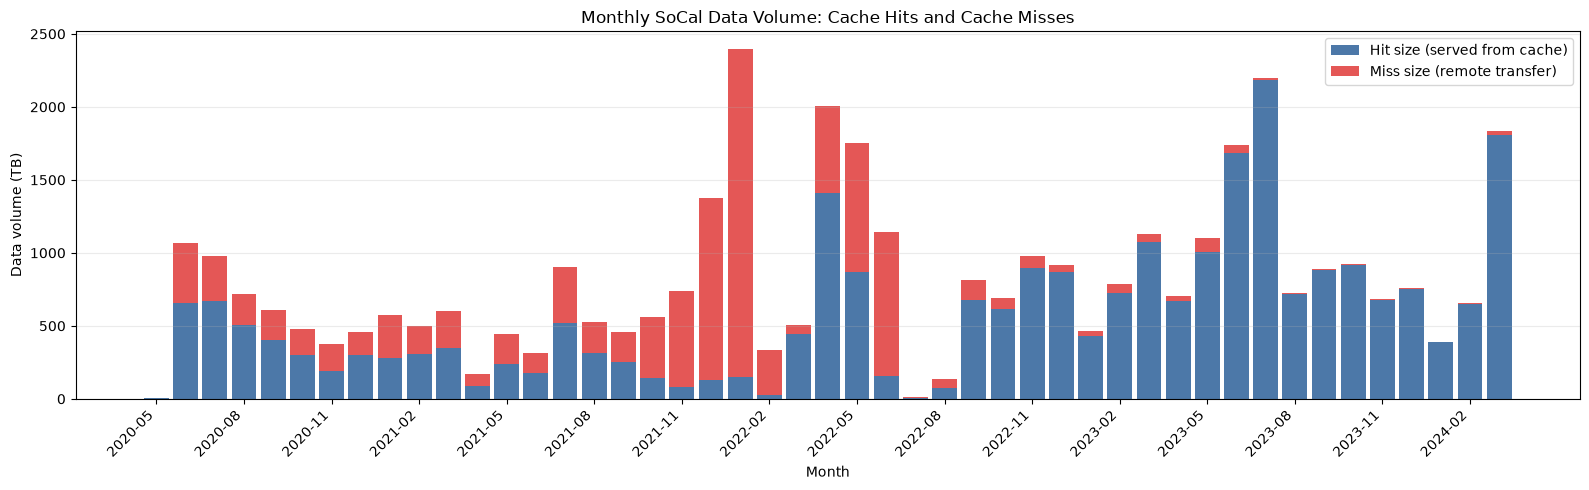

In [5]:
# Monthly traffic composition: local cache hits versus remote transfers (cache misses).
import numpy as np
monthly_size = df[['hit_size', 'miss_size']].resample('ME').sum()
month_positions = np.arange(len(monthly_size))
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(month_positions, monthly_size['hit_size'], color='#4C78A8',
       width=0.85, label='Hit size (served from cache)')
ax.bar(month_positions, monthly_size['miss_size'], bottom=monthly_size['hit_size'],
       color='#E45756', width=0.85, label='Miss size (remote transfer)')
ax.set_title('Monthly SoCal Data Volume: Cache Hits and Cache Misses')
ax.set_ylabel('Data volume (TB)')
ax.set_xlabel('Month')
ax.legend()
ax.set_xticks(month_positions[::3])
ax.set_xticklabels([date.strftime('%Y-%m') for date in monthly_size.index[::3]], rotation=45, ha='right')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

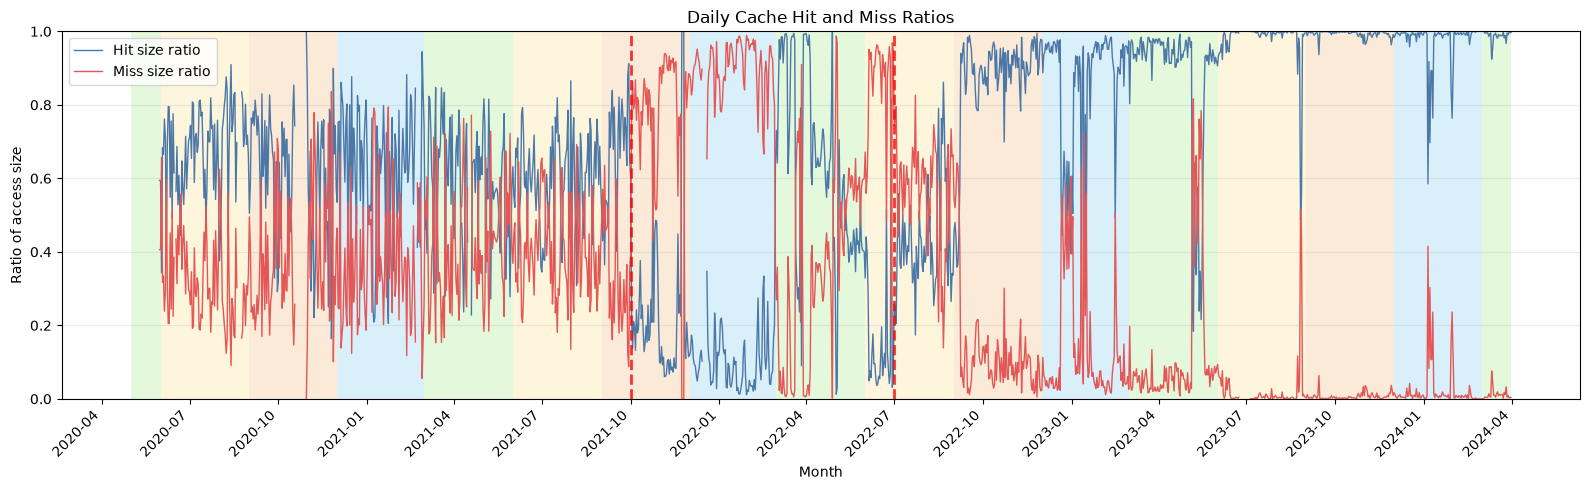

In [6]:
# Cache effectiveness over time: the proportion of access volume served locally or transferred remotely.
ratios = pd.DataFrame({
    'Hit size ratio': df['hit_size'].div(df['access_size']).where(df['access_size'] > 0),
    'Miss size ratio': df['miss_size'].div(df['access_size']).where(df['access_size'] > 0)
})
fig, ax = plt.subplots(figsize=(16, 5))
add_season_background(ax, df.index.min(), df.index.max())
ax.plot(ratios.index, ratios['Hit size ratio'], label='Hit size ratio', color='#4C78A8', linewidth=1)
ax.plot(ratios.index, ratios['Miss size ratio'], label='Miss size ratio', color='#E45756', linewidth=1)
for change_point in [pd.Timestamp('2021-10-01'), pd.Timestamp('2022-07-01')]:
    ax.axvline(change_point, color="#F80303", linestyle='--', linewidth=2, alpha=0.8)
ax.set_title('Daily Cache Hit and Miss Ratios')
ax.set_ylabel('Ratio of access size')
ax.set_xlabel('Month')
ax.set_ylim(0, 1)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.autofmt_xdate(rotation=45)
plt.tight_layout()
plt.show()

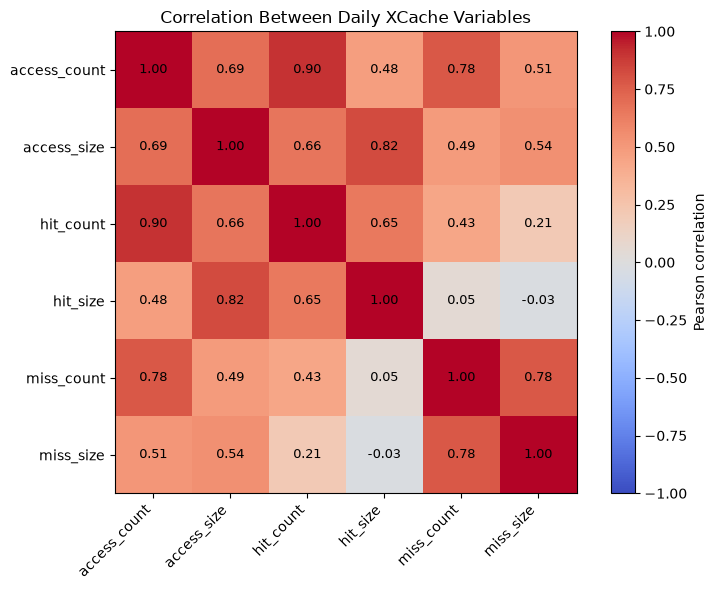

In [7]:
# Correlations show which variables move together; size variables are already expressed in TB.
correlation = df.corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlation.index)), correlation.index)
for row in range(len(correlation.index)):
    for col in range(len(correlation.columns)):
        ax.text(col, row, f'{correlation.iloc[row, col]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(image, ax=ax, label='Pearson correlation')
ax.set_title('Correlation Between Daily XCache Variables')
plt.tight_layout()
plt.show()

### Chicago and Boston Daily Data Visualization

The following plots use the same six daily XCache variables as the SoCal exploration. Colors distinguish meteorological seasons, and monthly labels provide a common time scale for each regional cache.


Chicago: 549 daily observations, 2022-09-30 to 2024-03-31
Boston: 213 daily observations, 2023-07-31 to 2024-02-28


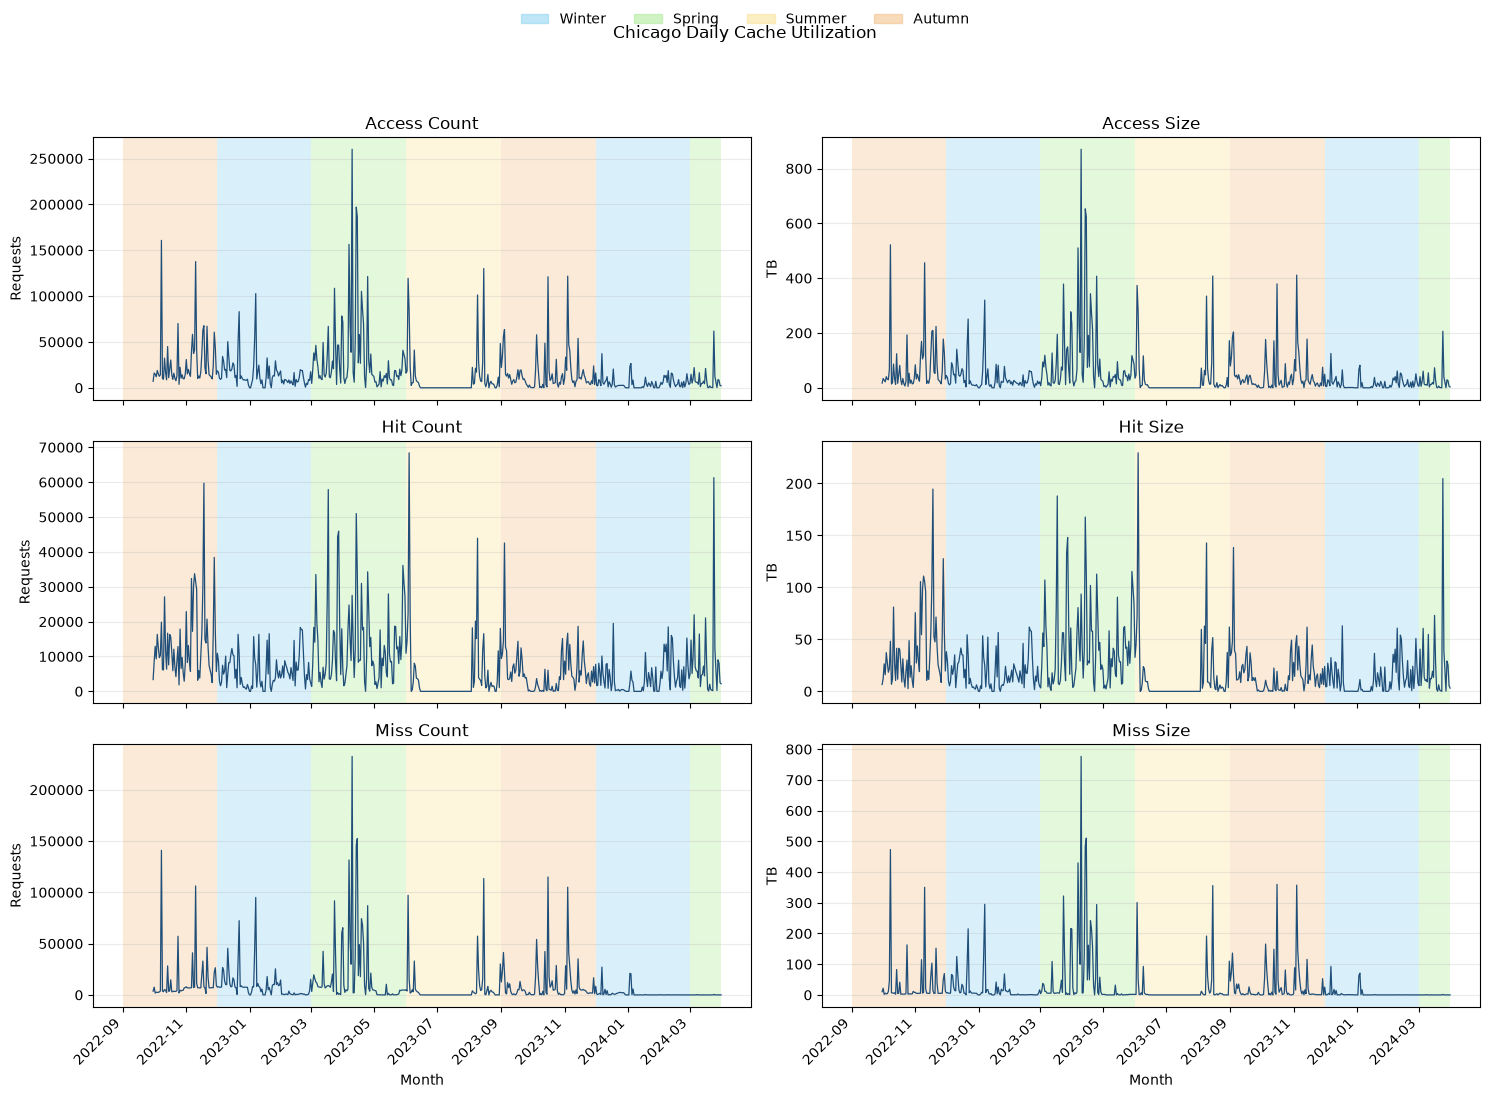

<Figure size 1100x1100 with 0 Axes>

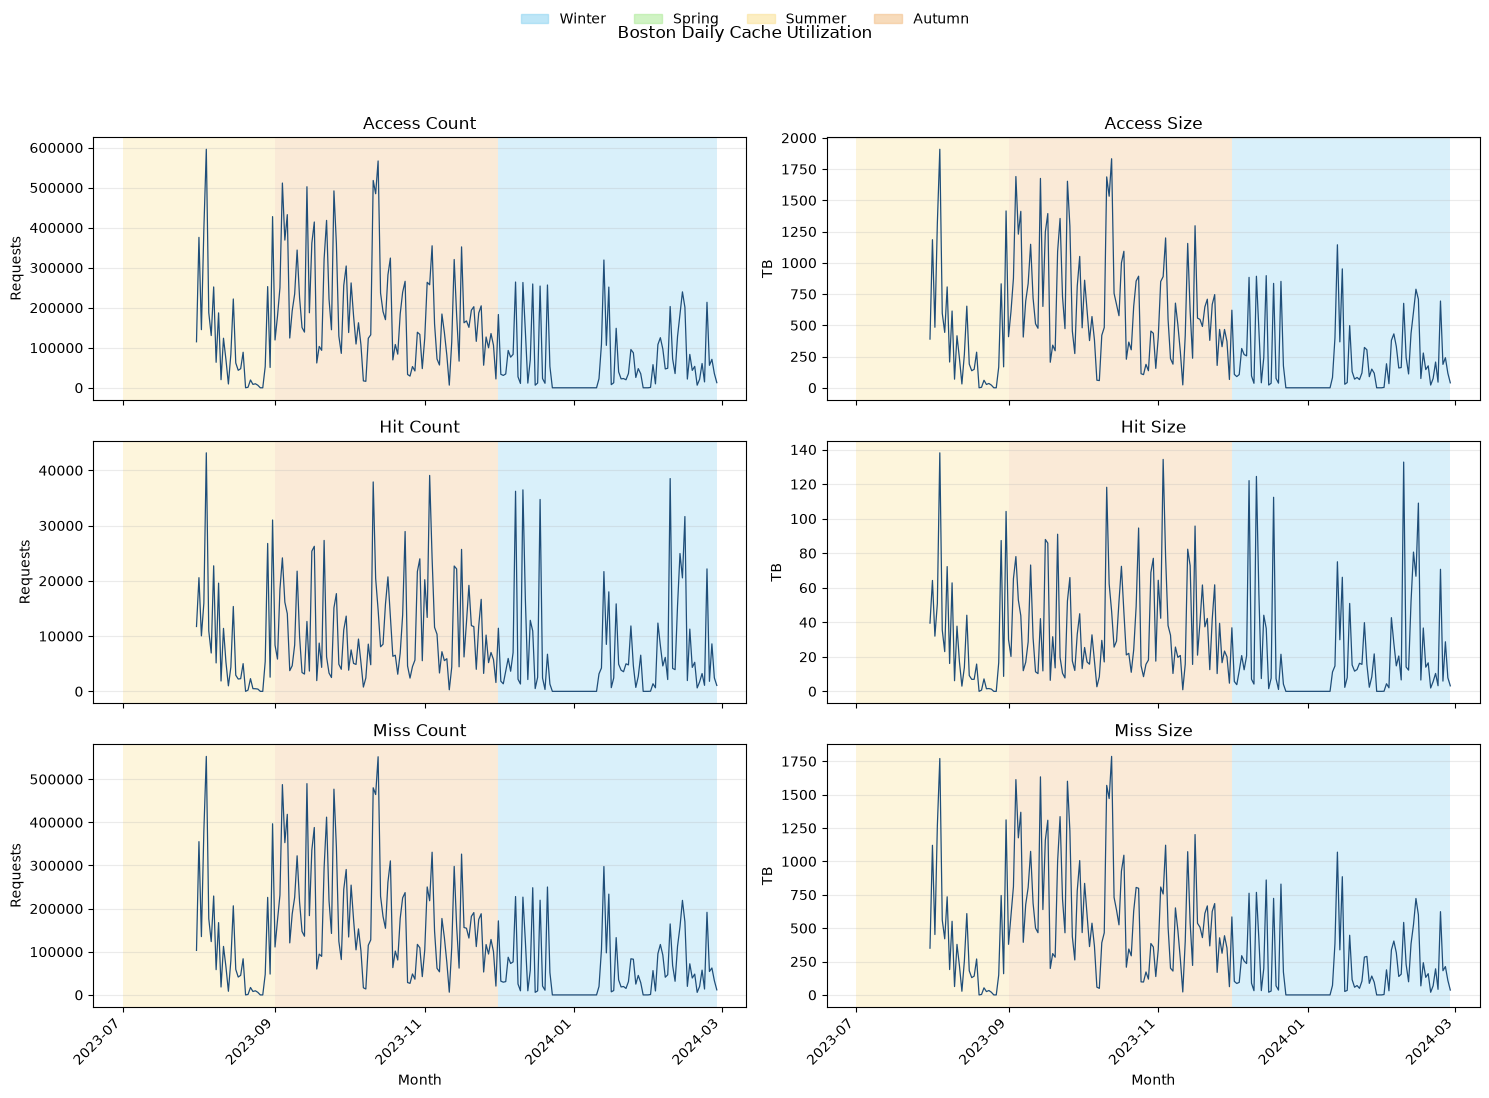

<Figure size 1100x1100 with 0 Axes>

In [13]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

def load_daily_region(region_prefix):
    region_df = pd.read_pickle(data_dir / f'{region_prefix}-daily-ml').copy()
    region_df[size_columns] = region_df[size_columns] / BYTES_PER_TB
    return region_df

chicago_df = load_daily_region('chic-2210-2403')
boston_df = load_daily_region('bost-2308-2403')
print(f'Chicago: {len(chicago_df)} daily observations, {chicago_df.index.min().date()} to {chicago_df.index.max().date()}')
print(f'Boston: {len(boston_df)} daily observations, {boston_df.index.min().date()} to {boston_df.index.max().date()}')

season_colors = {
    'Winter': "#94D6F2",  # Dec-Feb
    'Spring': "#B2EB9D",  # Mar-May
    'Summer': "#FBE39C",  # Jun-Aug
    'Autumn': "#F3C38F"   # Sep-Nov
}

month_to_season = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

def add_region_season_background(ax, start_date, end_date):
    month_starts = pd.date_range(start_date.normalize().replace(day=1),
                                 end_date + pd.offsets.MonthBegin(1), freq='MS')
    for start in month_starts:
        end = min(start + pd.offsets.MonthBegin(1), end_date)
        if end > start:
            ax.axvspan(start, end, color=season_colors[month_to_season[start.month]],
                       alpha=0.35, linewidth=0)

def plot_region_daily(region_df, region_name):
    fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
    for ax, column in zip(axes.flat, region_df.columns):
        add_region_season_background(ax, region_df.index.min(), region_df.index.max())
        ax.plot(region_df.index, region_df[column], color='#1F4E79', linewidth=0.9)
        ax.set_title(column.replace('_', ' ').title())
        ax.set_ylabel('Requests' if 'count' in column else 'TB')
        ax.grid(axis='y', alpha=0.25)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    for ax in axes[-1]:
        ax.set_xlabel('Month')
    legend_handles = [plt.Rectangle((0, 0), 1, 1, color=color, alpha=0.6, label=season)
                      for season, color in season_colors.items()]
    fig.legend(handles=legend_handles, loc='upper center', ncol=4, frameon=False)
    fig.suptitle(f'{region_name} Daily Cache Utilization', y=0.98)
    fig.autofmt_xdate(rotation=45)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
    plt.figure(figsize=(11, 11))


plot_region_daily(chicago_df, 'Chicago')
plot_region_daily(boston_df, 'Boston')

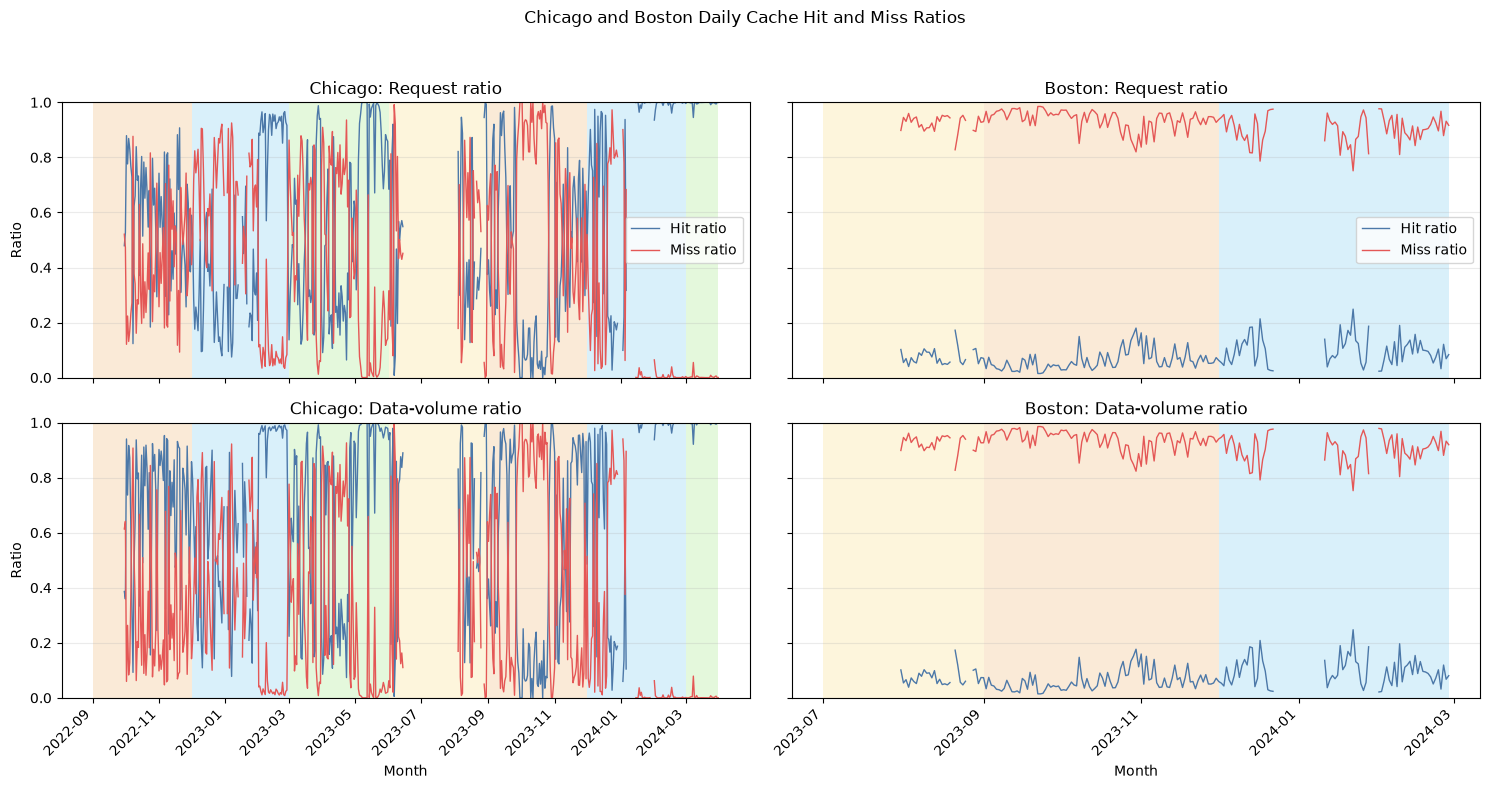

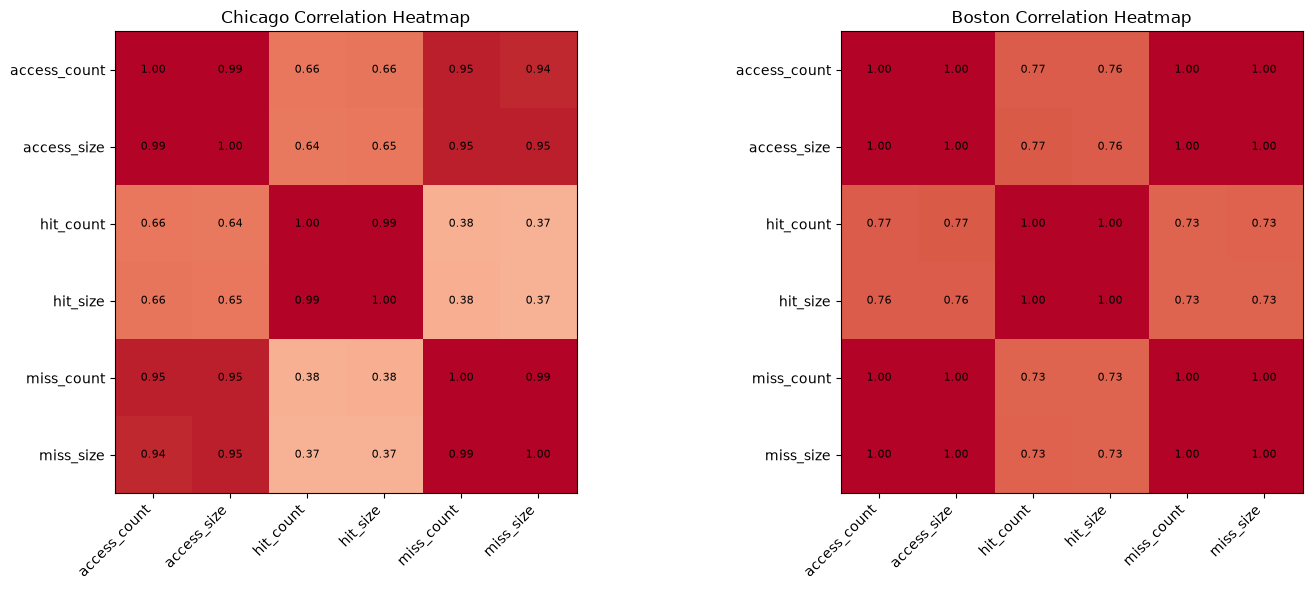

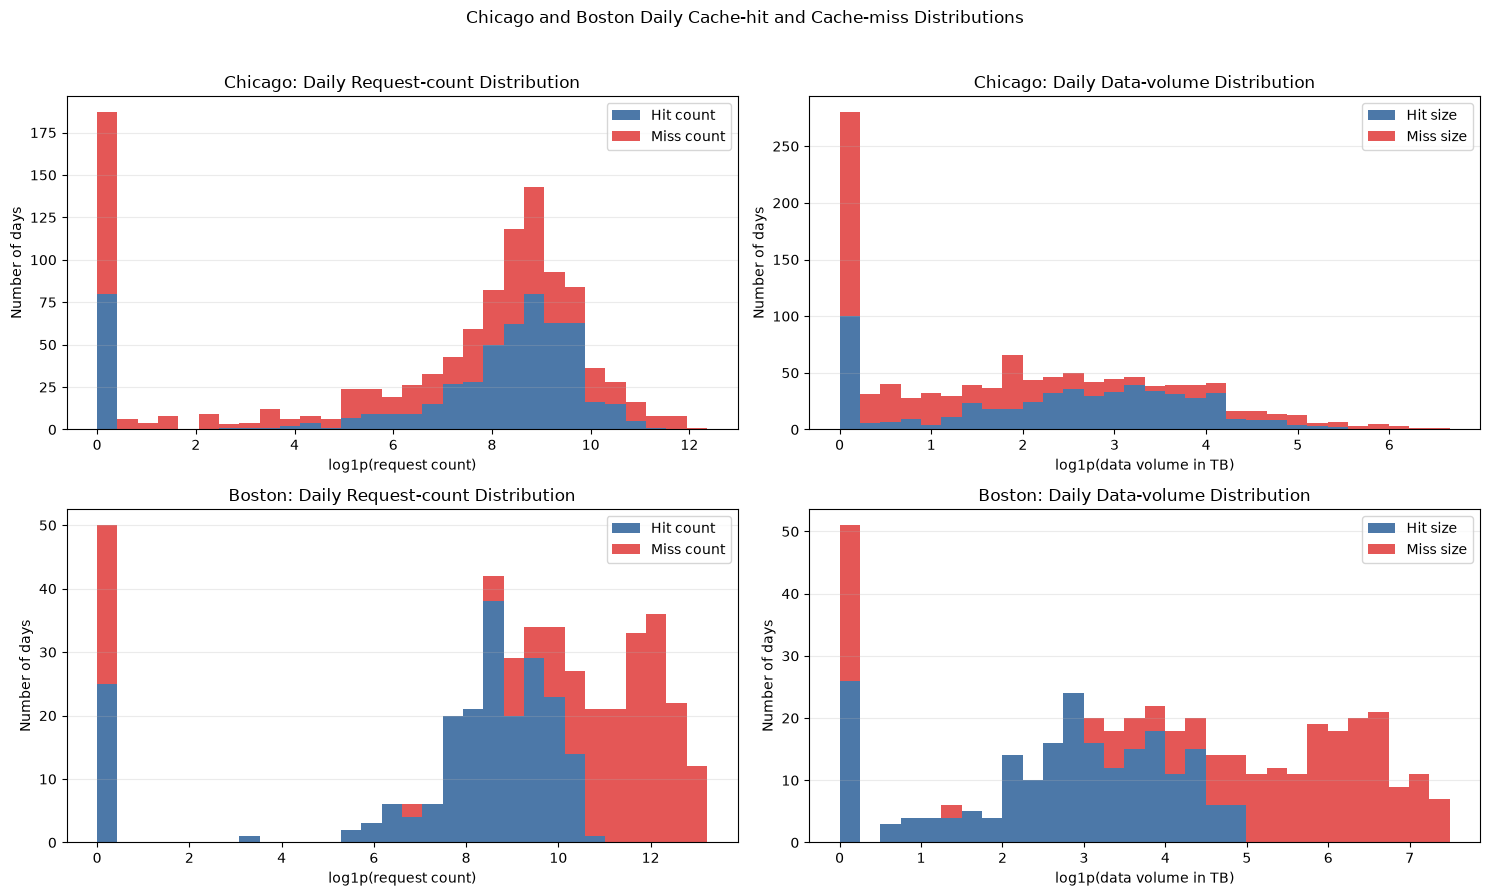

In [14]:
# Additional Chicago and Boston visualizations: cache ratios, correlations, and distributions.
import numpy as np
regional_data = {'Chicago': chicago_df, 'Boston': boston_df}
hit_color, miss_color = '#4C78A8', '#E45756'

# 1. Daily hit and miss ratios for request counts and data volumes.
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex='col', sharey='row')
for column, (region_name, region_df) in enumerate(regional_data.items()):
    count_hit_ratio = region_df['hit_count'].div(region_df['access_count']).where(region_df['access_count'] > 0)
    size_hit_ratio = region_df['hit_size'].div(region_df['access_size']).where(region_df['access_size'] > 0)
    for ax, hit_ratio, label in [(axes[0, column], count_hit_ratio, 'Request ratio'),
                                 (axes[1, column], size_hit_ratio, 'Data-volume ratio')]:
        add_region_season_background(ax, region_df.index.min(), region_df.index.max())
        ax.plot(region_df.index, hit_ratio, label='Hit ratio', color=hit_color, linewidth=1)
        ax.plot(region_df.index, 1 - hit_ratio, label='Miss ratio', color=miss_color, linewidth=1)
        ax.set_title(f'{region_name}: {label}')
        ax.set_ylim(0, 1)
        ax.grid(axis='y', alpha=0.25)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    axes[0, column].legend()
    axes[1, column].set_xlabel('Month')
axes[0, 0].set_ylabel('Ratio')
axes[1, 0].set_ylabel('Ratio')
fig.suptitle('Chicago and Boston Daily Cache Hit and Miss Ratios', y=0.98)
fig.autofmt_xdate(rotation=45)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 2. Pearson correlation heatmaps for the six daily variables.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (region_name, region_df) in zip(axes, regional_data.items()):
    correlation = region_df.corr()
    image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(correlation.index)), correlation.index)
    for row in range(len(correlation.index)):
        for col in range(len(correlation.columns)):
            ax.text(col, row, f'{correlation.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8)
    ax.set_title(f'{region_name} Correlation Heatmap')
plt.tight_layout()
plt.show()

# 3. Distributions of daily cache hits and misses. Log1p reveals both ordinary days and large spikes.
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for row, (region_name, region_df) in enumerate(regional_data.items()):
    axes[row, 0].hist([np.log1p(region_df['hit_count']), np.log1p(region_df['miss_count'])],
                      bins=30, stacked=True, color=[hit_color, miss_color],
                      label=['Hit count', 'Miss count'])
    axes[row, 0].set_title(f'{region_name}: Daily Request-count Distribution')
    axes[row, 0].set_xlabel('log1p(request count)')
    axes[row, 0].set_ylabel('Number of days')
    axes[row, 0].legend()
    axes[row, 0].grid(axis='y', alpha=0.25)

    axes[row, 1].hist([np.log1p(region_df['hit_size']), np.log1p(region_df['miss_size'])],
                      bins=30, stacked=True, color=[hit_color, miss_color],
                      label=['Hit size', 'Miss size'])
    axes[row, 1].set_title(f'{region_name}: Daily Data-volume Distribution')
    axes[row, 1].set_xlabel('log1p(data volume in TB)')
    axes[row, 1].set_ylabel('Number of days')
    axes[row, 1].legend()
    axes[row, 1].grid(axis='y', alpha=0.25)
fig.suptitle('Chicago and Boston Daily Cache-hit and Cache-miss Distributions', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Dataset Exploration Summary

The XCache dataset records network utilization associated with scientific data accesses at regional caches. Each observation is aggregated at either a daily or hourly time resolution. This preliminary exploration uses the multivariate (`*-ml`) dataset, which contains six network-utilization features:

- `access_count`: Number of cache requests in each interval
- `access_size`: Total data volume of those requests (TB)
- `hit_count`: Number of requests served directly from cache
- `hit_size`: Total data volume served from cache (TB)
- `miss_count`: Number of requests that missed the cache
- `miss_size`: Total data volume transferred from origin (TB)

The features have two deterministic relationships: 
- `access_count = hit_count + miss_count`
- `access_size = hit_size + miss_size`

These six features are NOT independent, we can reformulate the prediction target into four independent variables that separate traffic volume from cache behavior:
- `log(access count)`
- `log(access size)`
- `hit count ratio` = `hit count` / `access count`
- `hit size ratio` = `hit size` / `access size`

### Model 
- Model: TCN
- Baseline Model: TBD 

- Features: 
- Origin features: `access_count`, `access_size`, `hit_count`, `hit_size`, `miss_count`, `miss_size`
- Other features: `log_access_count` = log1p(access_count), `log_access_size`  = log1p(access_size), `hit_count_ratio` = hit_count / access_count, `hit_size_ratio`  = hit_size / access_size, `miss_count_ratio` = miss_count / access_count, `miss_size_ratio`  = miss_size / access_size, `network_demand_reduction_rate` = access_size / miss_size, `data_reuse_rate` =  (sum of reuses) / (total number of unique files) = (cache hits) / (# of unique files)

- Primary metric of interest: RMSE

- Training window and prediction window: TBD
- Train TCN on SoCal → Fine-tune on Chicago → Fine-tune on Boston

Questions:
1. dataset should use: 
    socal:
    [7/2022, end] fitting better 
    or 
    [start, end] using all data (icnc27-xcache_ts.pdf used all data)

2. which model should be used as baseline? 
    LSTM? or the best model from the latest paper?

3. Long term forecasting - how? 
    Current time window (1 day or 1 hour), extend to a longer term such as 1 week or 30 days  (multi-variate, multi-step time forecasting)
    eg. previous 28 days - then predict the next 7 days?



